In [ ]:
from pathlib import Path
import sys
_here = Path.cwd().resolve()
_candidates = [_here, *_here.parents]
PROJECT_ROOT = next((p for p in _candidates if (p / "data" / "raw" / "era5_algeria_raw.nc").exists()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Start Jupyter from the project root or notebooks/ folder.")
sys.path.insert(0, str(PROJECT_ROOT / "src"))

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from climate_utils import make_algeria_mask

plt.style.use("seaborn-v0_8-whitegrid")
print("Project root:", PROJECT_ROOT)
raw_path = PROJECT_ROOT / "data" / "raw" / "era5_algeria_raw.nc"
geojson_path = PROJECT_ROOT / "data" / "raw" / "dz.json"
assert raw_path.exists(), raw_path
assert geojson_path.exists(), geojson_path

ds_raw = xr.open_dataset(raw_path)
print(ds_raw)
print("Dimensions des données:", dict(ds_raw.sizes))
print("Coordonnées:", list(ds_raw.coords))
print("Variables:", list(ds_raw.data_vars))

Project root: C:\Users\hp\Downloads\Climate_Data_Mining_Algeria\Climate_Data_Mining_Algeria\Climate_Data_Mining
<xarray.Dataset> Size: 273MB
Dimensions:     (valid_time: 141, latitude: 191, longitude: 211)
Coordinates:
  * valid_time  (valid_time) datetime64[ns] 1kB 2015-01-01 ... 2026-09-01
    expver      (valid_time) <U4 2kB ...
  * latitude    (latitude) float64 2kB 37.5 37.4 37.3 37.2 ... 18.7 18.6 18.5
  * longitude   (longitude) float64 2kB -9.0 -8.9 -8.8 -8.7 ... 11.8 11.9 12.0
    number      int64 8B ...
Data variables:
    d2m         (valid_time, latitude, longitude) float32 23MB ...
    t2m         (valid_time, latitude, longitude) float32 23MB ...
    slhf        (valid_time, latitude, longitude) float32 23MB ...
    ssr         (valid_time, latitude, longitude) float32 23MB ...
    str         (valid_time, latitude, longitude) float32 23MB ...
    sshf        (valid_time, latitude, longitude) float32 23MB ...
    ro          (valid_time, latitude, longitude) float32 23MB

## Index des variables et attributs

In [9]:
schema = pd.DataFrame([
    {
        "variable": name,
        "dimensions": ", ".join(da.dims),
        "dtype": str(da.dtype),
        "units": da.attrs.get("units", "non enregistré"),
        "long_name": da.attrs.get("long_name", ""),
    }
    for name, da in ds_raw.data_vars.items()
])
display(schema)

,variable,dimensions,dtype,units,long_name
0,d2m,"valid_time, latitude, longitude",float32,K,2 metre dewpoint temperature
1,t2m,"valid_time, latitude, longitude",float32,K,2 metre temperature
2,slhf,"valid_time, latitude, longitude",float32,J m**-2,Time-integrated surface latent heat net flux
3,ssr,"valid_time, latitude, longitude",float32,J m**-2,Surface net short-wave (solar) radiation
4,str,"valid_time, latitude, longitude",float32,J m**-2,Surface net long-wave (thermal) radiation
5,sshf,"valid_time, latitude, longitude",float32,J m**-2,Time-integrated surface sensible heat net flux
6,ro,"valid_time, latitude, longitude",float32,m,Runoff
7,e,"valid_time, latitude, longitude",float32,m of water equivalent,Evaporation
8,u10,"valid_time, latitude, longitude",float32,m s**-1,10 metre U wind component
9,v10,"valid_time, latitude, longitude",float32,m s**-1,10 metre V wind component


In [10]:
times = pd.to_datetime(ds_raw["valid_time"].values)
print("Période:", times.min(), "à", times.max())
print("Nombre de moments:", len(times))
print("Dates triées ?", times.is_monotonic_increasing)
print("Doublons temporels:", int(times.duplicated().sum()))
if len(times) > 1:
    print("Intervalles temporels courants:", pd.Series(times[1:] - times[:-1]).value_counts().head())
print("Étendue de la longitude:", float(ds_raw.longitude.min()), "à", float(ds_raw.longitude.max()))
print("Étendue de la latitude:", float(ds_raw.latitude.min()), "à", float(ds_raw.latitude.max()))
expver = pd.Series(ds_raw["expver"].values, index=times.strftime("%Y-%m"))
print("Versions des données (expver) :", expver.value_counts().to_dict())
print("Mois en version préliminaire ERA5T (0005, encore révisables) :", expver[expver == "0005"].index.tolist())

Période: 2015-01-01 00:00:00 à 2026-09-01 00:00:00
Nombre de moments: 141
Dates triées ? True
Doublons temporels: 0
Intervalles temporels courants: 31 days    82
30 days    46
28 days     9
29 days     3
Name: count, dtype: int64
Étendue de la longitude: -9.0 à 12.0
Étendue de la latitude: 18.5 à 37.5
Versions des données (expver) : {'0001': 139, '0005': 2}
Mois en version préliminaire ERA5T (0005, encore révisables) : ['2026-08', '2026-09']


## Création du masque géographique


In [11]:
mask, algeria = make_algeria_mask(ds_raw, PROJECT_ROOT)
ds_algeria = ds_raw.where(mask)
valid_t2m_cells = int(ds_algeria["t2m"].notnull().any("valid_time").sum().values)
print("Forme de la grille originale:", ds_raw["t2m"].shape[1:])
print("Centres des cellules à l'intérieur du polygone:", int(mask.sum().values))
print("Cellules à l'intérieur du polygone ayant une valeur de température au moins une fois:", valid_t2m_cells)
print("Cellules à l'intérieur du polygone sans température pendant toute la période:", int((mask & ds_algeria.t2m.isnull().all("valid_time")).sum().values))
print("Intégrité du polygone:", algeria.is_valid, "; limites:", algeria.bounds)

Forme de la grille originale: (191, 211)
Centres des cellules à l'intérieur du polygone: 21257
Cellules à l'intérieur du polygone ayant une valeur de température au moins une fois: 21245
Cellules à l'intérieur du polygone sans température pendant toute la période: 12
Intégrité du polygone: True ; limites: (-8.68238521619834, 18.97556113605486, 11.968860720039096, 37.09393951787425)


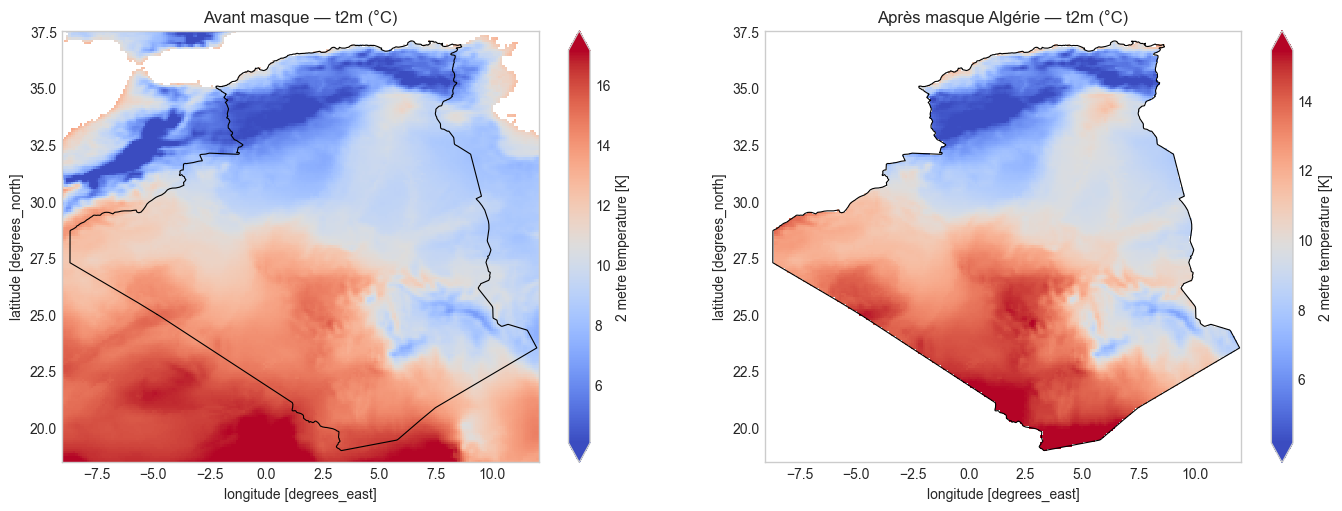

In [12]:
t_index = 0
fig, axes = plt.subplots(1, 2, figsize=(14, 5), constrained_layout=True)
for ax, da, title in [
    (axes[0], ds_raw.t2m.isel(valid_time=t_index) - 273.15, "Avant masque — t2m (°C)"),
    (axes[1], ds_algeria.t2m.isel(valid_time=t_index) - 273.15, "Après masque Algérie — t2m (°C)"),
]:
    da.plot.pcolormesh(ax=ax, x="longitude", y="latitude", cmap="coolwarm", robust=True, add_colorbar=True)
    for geom in getattr(algeria, "geoms", [algeria]):
        x, y = geom.exterior.xy
        ax.plot(x, y, color="black", linewidth=0.8)
    ax.set_title(title)
    ax.set_aspect("equal")
plt.show()

## Réduction spatiale pour l'affichage et la taille

In [13]:
n_lat = ds_algeria.sizes["latitude"]
n_lon = ds_algeria.sizes["longitude"]

print("Dimensions initiales :")
print("Latitude :", n_lat)
print("Longitude :", n_lon)


n_blocks_lat = n_lat // 2
n_blocks_lon = n_lon // 2

total_blocks = n_blocks_lat * n_blocks_lon

print("\nNombre de blocs 2x2 :")
print("Blocs en latitude :", n_blocks_lat)
print("Blocs en longitude :", n_blocks_lon)
print("Nombre total de blocs :", total_blocks)

reduced = ds_algeria.coarsen(
    latitude=2,
    longitude=2,
    boundary="trim"
).mean(keep_attrs=True)

output_dir = PROJECT_ROOT / "data" / "processed"
output_dir.mkdir(parents=True, exist_ok=True)

reduced_path = output_dir / "era5_algeria_masked_2x2_v2.nc"


encoding = {
    name: {
        "zlib": True,
        "complevel": 4,
        "dtype": "float32"
    }
    for name in reduced.data_vars
}


reduced.to_netcdf(
    path=reduced_path,
    engine="netcdf4",
    encoding=encoding,
    mode="w"
)


check = xr.open_dataset(reduced_path)

print("\nDimensions après réduction :")
print(dict(check.sizes))

print("\nNombre de cellules après réduction :",
      check.sizes["latitude"] * check.sizes["longitude"])

print("\nFichier sauvegardé :", reduced_path)
print("Taille :", round(reduced_path.stat().st_size / 1e6, 2), "MB")


check.close()

Dimensions initiales :
Latitude : 191
Longitude : 211

Nombre de blocs 2x2 :
Blocs en latitude : 95
Blocs en longitude : 105
Nombre total de blocs : 9975

Dimensions après réduction :
{'valid_time': 141, 'latitude': 95, 'longitude': 105}

Nombre de cellules après réduction : 9975

Fichier sauvegardé : C:\Users\hp\Downloads\Climate_Data_Mining_Algeria\Climate_Data_Mining_Algeria\Climate_Data_Mining\data\processed\era5_algeria_masked_2x2_v2.nc
Taille : 23.11 MB


## Contrôles de la réduction 2×2

Deux points à vérifier : (1) `boundary="trim"` supprime la dernière ligne et la dernière colonne de la grille (nombre impair de points) : contiennent-elles des cellules algériennes ? (2) `coarsen().mean()` ignore les NaN : une cellule réduite peut donc être la moyenne de moins de 4 sous-cellules (bords du pays, côte nord). Ces cellules sont repérées ici et traitées dans le notebook 03.

In [14]:
lost_lat = int(mask.isel(latitude=slice(2 * n_blocks_lat, None)).sum())
lost_lon = int(mask.isel(longitude=slice(2 * n_blocks_lon, None)).sum())
print("Cellules algériennes supprimées par boundary='trim' :", lost_lat + lost_lon)

land_in_dz = (mask & ds_raw["t2m"].notnull().all("valid_time")).astype(float)
n_sub = land_in_dz.coarsen(latitude=2, longitude=2, boundary="trim").sum().values
vals, cnts = np.unique(n_sub[n_sub > 0], return_counts=True)
print("Nombre de sous-cellules valides par cellule réduite :", dict(zip(vals.astype(int).tolist(), cnts.tolist())))
print(f"Cellules réduites incomplètes (< 4 sous-cellules) : {int(((n_sub > 0) & (n_sub < 4)).sum())} "
      f"sur {int((n_sub > 0).sum())} ({100 * ((n_sub > 0) & (n_sub < 4)).sum() / (n_sub > 0).sum():.2f} %)")

Cellules algériennes supprimées par boundary='trim' : 0
Nombre de sous-cellules valides par cellule réduite : {1: 74, 2: 78, 3: 73, 4: 5199}
Cellules réduites incomplètes (< 4 sous-cellules) : 225 sur 5424 (4.15 %)
